# Thí Nghiệm Trực Quan: Bản Chất Của Việc Thu Nhỏ Ảnh (Resize / Interpolation)
> **Mục tiêu:** Nhìn tận mắt toán học bên dưới việc biến ma trận $256\times256$ thành $224\times224$ (và thu cực nhỏ về $8\times8$ để thấy từng viên gạch số).

In [1]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Đọc ảnh lá cà chua bằng đường dẫn tương đối linh hoạt
img_path = 'data/train/Tomato___Tomato_Yellow_Leaf_Curl_Virus/966393c2-cef5-4fe7-b6e2-e6f6b7cfac0a___UF.GRC_YLCV_Lab 01569.JPG'
if not os.path.exists(img_path):
    img_path = '../' + img_path

img_goc = Image.open(img_path)
print("Đã tải thành công ảnh!")
print("Kích thước gốc:", img_goc.size, "(Tổng số pixel:", img_goc.size[0] * img_goc.size[1], ")")

Đã tải thành công ảnh!
Kích thước gốc: (256, 256) (Tổng số pixel: 65536 )


### Thí nghiệm 1: So sánh trực tiếp Ảnh Gốc (256x256) vs Ảnh Chuẩn Hóa (224x224)
Mắt người nhìn vào gần như không thấy sự suy giảm độ nét, nhưng máy tính đã giảm được hơn 15.000 điểm ảnh (giảm 23% gánh nặng tính toán)!

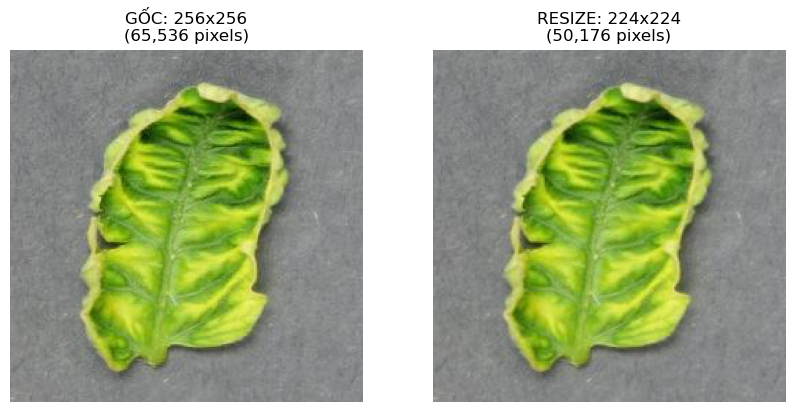

In [2]:
img_224 = img_goc.resize((224, 224))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_goc)
axes[0].set_title(f"GỐC: 256x256\n({256*256:,} pixels)")
axes[0].axis('off')

axes[1].imshow(img_224)
axes[1].set_title(f"RESIZE: 224x224\n({224*224:,} pixels)")
axes[1].axis('off')
plt.show()

### Thí nghiệm 2: "Soi kính hiển vi" vào một mẩu đốm bệnh nhỏ (4x4 pixels)
Ta cắt một mẩu đốm bệnh nhỏ $4\times4$ pixel từ ảnh $256$, rồi resize nó về $2\times2$ để bạn thấy chính xác các con số toán học được gom trung bình ra sao!

--- MA TRẬN 4x4 PIXELS BAN ĐẦU ---
[[126 134 140 143]
 [122 129 132 133]
 [137 138 138 136]
 [151 149 148 148]]

--- MA TRẬN 2x2 SAU KHI NỘI SUY (GOM LẠI) ---
[[130 136]
 [141 141]]


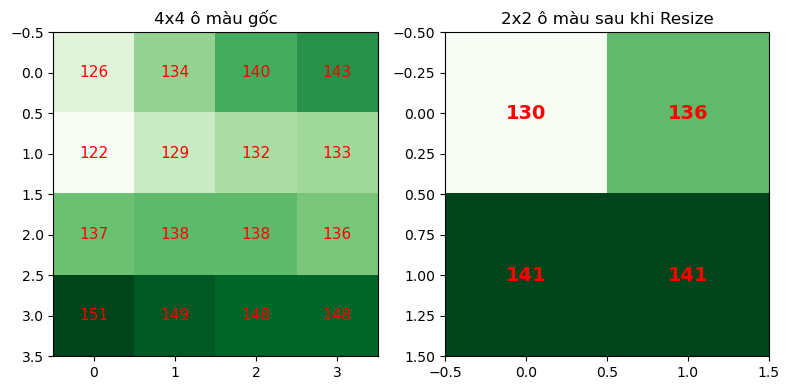

In [3]:
# Cắt 1 mẩu nhỏ 4x4 pixel tại tọa độ (100, 100) trên kênh màu Xanh lá (Green)
arr_green = np.array(img_goc)[:, :, 1] # Kênh 1 là Green
mau_4x4 = arr_green[100:104, 100:104]

print("--- MA TRẬN 4x4 PIXELS BAN ĐẦU ---")
print(mau_4x4)

# Chuyển mẩu này thành ảnh để resize về 2x2 bằng thuật toán Bilinear (nội suy)
img_crop = Image.fromarray(mau_4x4)
img_crop_2x2 = img_crop.resize((2, 2), Image.BILINEAR)
mau_2x2 = np.array(img_crop_2x2)

print("\n--- MA TRẬN 2x2 SAU KHI NỘI SUY (GOM LẠI) ---")
print(mau_2x2)

# Vẽ trực quan các ô vuông màu số
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(mau_4x4, cmap='Greens')
ax[0].set_title("4x4 ô màu gốc")
for i in range(4):
    for j in range(4):
        ax[0].text(j, i, str(mau_4x4[i, j]), ha='center', va='center', color='red', fontsize=11)

ax[1].imshow(mau_2x2, cmap='Greens')
ax[1].set_title("2x2 ô màu sau khi Resize")
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, str(mau_2x2[i, j]), ha='center', va='center', color='red', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### Thí nghiệm 3: Xem 3 kênh màu TÁCH RỜI (Red, Green, Blue)
Hãy xem vùng lá xanh và đốm bệnh xuất hiện thế nào trên từng kênh riêng biệt!

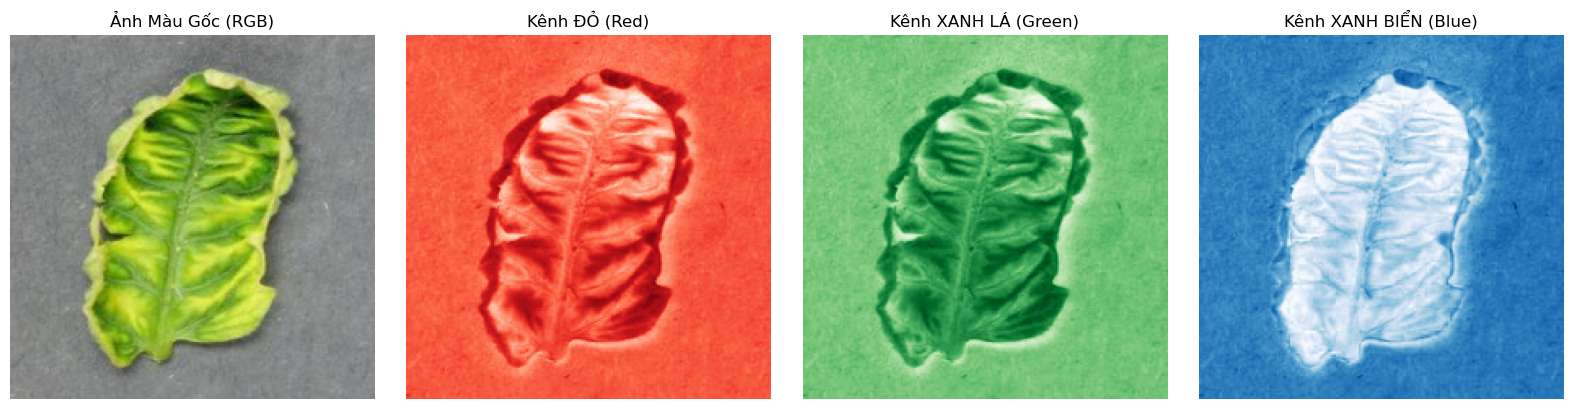

In [4]:
arr_224 = np.array(img_224)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(arr_224)
axes[0].set_title("Ảnh Màu Gốc (RGB)")
axes[0].axis('off')

axes[1].imshow(arr_224[:, :, 0], cmap='Reds')
axes[1].set_title("Kênh ĐỎ (Red)")
axes[1].axis('off')

axes[2].imshow(arr_224[:, :, 1], cmap='Greens')
axes[2].set_title("Kênh XANH LÁ (Green)")
axes[2].axis('off')

axes[3].imshow(arr_224[:, :, 2], cmap='Blues')
axes[3].set_title("Kênh XANH BIỂN (Blue)")
axes[3].axis('off')

plt.tight_layout()
plt.show()